<a href="https://colab.research.google.com/github/JabbarHakim/Vision-Computer/blob/main/Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub tensorflow scikit-learn matplotlib seaborn

In [2]:
import os
import kagglehub

# Download dataset dari Kaggle
path = kagglehub.dataset_download(
    "mikoajfish99/lions-or-cheetahs-image-classification"
)

print("Path to dataset files:", path)

# Periksa struktur folder dataset
for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")
    if root.count(os.sep) - path.count(os.sep) >= 2:
        dirs[:] = []

100%|██████████| 71.3M/71.3M [00:00<00:00, 177MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1
/root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1 -> 0 files
/root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1/images -> 0 files
/root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1/images/Cheetahs -> 100 files
/root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1/images/Lions -> 100 files


In [5]:
import tensorflow as tf
from pathlib import Path

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

# Find the directory containing both class folders
expected_classes = {"lions", "cheetahs"}
data_dir = None

for folder in Path(path).rglob("*"):
    if folder.is_dir():
        subdirs = {
            item.name.lower()
            for item in folder.iterdir()
            if item.is_dir()
        }

        if expected_classes.issubset(subdirs):
            data_dir = folder
            break

if data_dir is None:
    raise FileNotFoundError(
        "Lion and cheetah class folders were not found. "
        "Check the dataset structure printed in Step A."
    )

print("Image directory:", data_dir)

# Load 70% of the data for training
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cheetahs", "Lions"]
)

# Load the remaining 30%
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cheetahs", "Lions"]
)

# Split the remaining data into validation and testing
n_batches = tf.data.experimental.cardinality(
    val_test_ds
).numpy()

if n_batches < 2:
    raise ValueError(
        "There is insufficient data to create separate "
        "validation and testing subsets."
    )

val_ds = val_test_ds.take(n_batches // 2)
test_ds = val_test_ds.skip(n_batches // 2)

# Normalize pixel values to the range 0–1
normalization = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y)
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (normalization(x), y)
).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (normalization(x), y)
).prefetch(tf.data.AUTOTUNE)

print("Class mapping: Cheetahs = 0, Lions = 1")

Image directory: /root/.cache/kagglehub/datasets/mikoajfish99/lions-or-cheetahs-image-classification/versions/1/images
Found 200 files belonging to 2 classes.
Using 140 files for training.
Found 200 files belonging to 2 classes.
Using 60 files for validation.
Class mapping: Cheetahs = 0, Lions = 1


In [6]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 704ms/step - accuracy: 0.4571 - loss: 1.3539 - val_accuracy: 0.4375 - val_loss: 0.7225
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 522ms/step - accuracy: 0.5286 - loss: 0.6783 - val_accuracy: 0.4375 - val_loss: 0.7074
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 754ms/step - accuracy: 0.6714 - loss: 0.6503 - val_accuracy: 0.4688 - val_loss: 0.7081
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 525ms/step - accuracy: 0.6571 - loss: 0.6210 - val_accuracy: 0.5000 - val_loss: 0.7031
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 712ms/step - accuracy: 0.8357 - loss: 0.5063 - val_accuracy: 0.5312 - val_loss: 0.7062
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 496ms/step - accuracy: 0.8000 - loss: 0.4253 - val_accuracy: 0.7188 - val_loss: 0.6014
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 619ms/step - accuracy: 0.9143 - loss: 0.3000 - val_accuracy: 0.6250 - val_loss: 0.6566
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 521ms/step - accuracy: 0.9500 - loss: 0.1836 - val_accuracy: 0.6250 - val_loss:

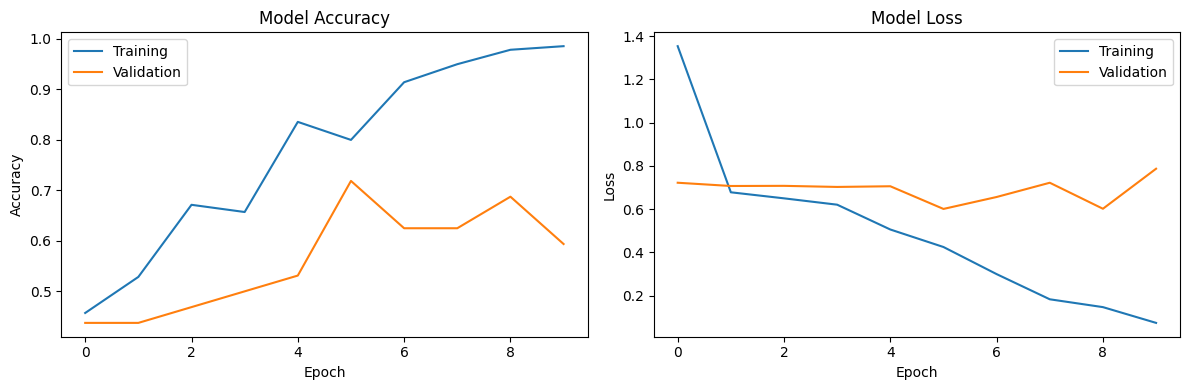

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

=== CNN EVALUATION RESULTS ===
Accuracy  : 0.5357 (53.57%)
Precision : 0.5556 (55.56%)
Recall    : 0.6667 (66.67%)
F1-score  : 0.6061 (60.61%)

Classification Report:
              precision    recall  f1-score   support

    Cheetahs       0.50      0.38      0.43        13
       Lions       0.56      0.67      0.61        15

    accuracy                           0.54        28
   macro avg       0.53      0.53      0.52        28
weighted avg       0.53      0.54      0.53        28



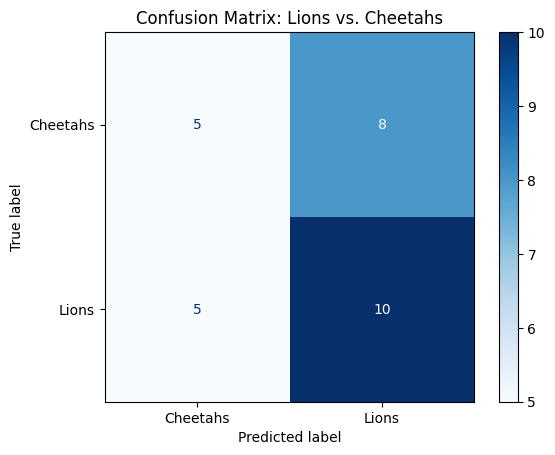

In [9]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Collect the actual labels from the testing dataset
y_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in test_ds
]).astype(int)

# Generate model predictions
y_prob = model.predict(test_ds, verbose=0).ravel()

# Convert probabilities into binary class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

# Display evaluation results
print("=== CNN EVALUATION RESULTS ===")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score  : {f1:.4f} ({f1 * 100:.2f}%)")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cheetahs", "Lions"],
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cheetahs", "Lions"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Lions vs. Cheetahs")
plt.show()